In [1]:
import pandas as pd

df = pd.read_csv("../data/10millionPasswords.csv")

print("Number of rows:", len(df))
print("Columns:", df.columns.tolist())

df.head()

Number of rows: 999997
Columns: ['rank', 'password']


,rank,password
0,1,123456
1,2,password
2,3,12345678
3,4,qwerty
4,5,123456789


In [2]:
# Calculate password length
df["length"] = df["password"].str.len()

# Divide passwords into two groups
short_passwords = df[df["length"] <= 8]
long_passwords = df[df["length"] > 8]

# Display results
print("Short passwords (<= 8):", len(short_passwords))
print("Long passwords (> 8):", len(long_passwords))
print("Missing passwords:", df["password"].isna().sum())

Short passwords (<= 8): 816946
Long passwords (> 8): 183048
Missing passwords: 3


In [3]:
# Check for duplicate passwords
print("Duplicate passwords:", df["password"].duplicated().sum())

# Check password length
print("Shortest password:", df["length"].min())
print("Longest password:", df["length"].max())

# Check for missing values
print("\nMissing values:")
print(df.isna().sum())

Duplicate passwords: 2
Shortest password: 3.0
Longest password: 39.0

Missing values:
rank        0
password    3
length      3
dtype: int64


In [4]:
# Show rows where the password is missing
df[df["password"].isna()]


,rank,password,length
20917,20918,NaN,NaN
49135,49136,NaN,NaN
282774,282775,NaN,NaN


In [5]:
# Read the dataset without converting text values to NaN
df_check = pd.read_csv(
    "../data/10millionPasswords.csv",
    dtype={"password": "string"},
    keep_default_na=False
)

# Show the three suspicious rows
df_check.loc[[20917, 49135, 282774]]

,rank,password
20917,20918,
49135,49136,None
282774,282775,


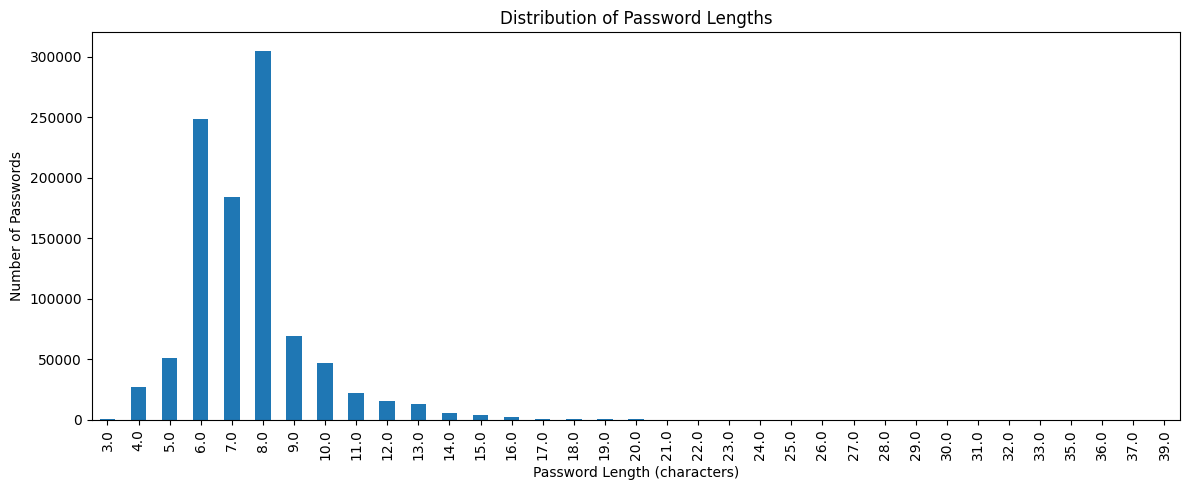

In [6]:
import matplotlib.pyplot as plt

# Count passwords by length
length_counts = df["length"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(12, 5))
length_counts.plot(kind="bar")

plt.title("Distribution of Password Lengths")
plt.xlabel("Password Length (characters)")
plt.ylabel("Number of Passwords")

plt.tight_layout()
plt.show()

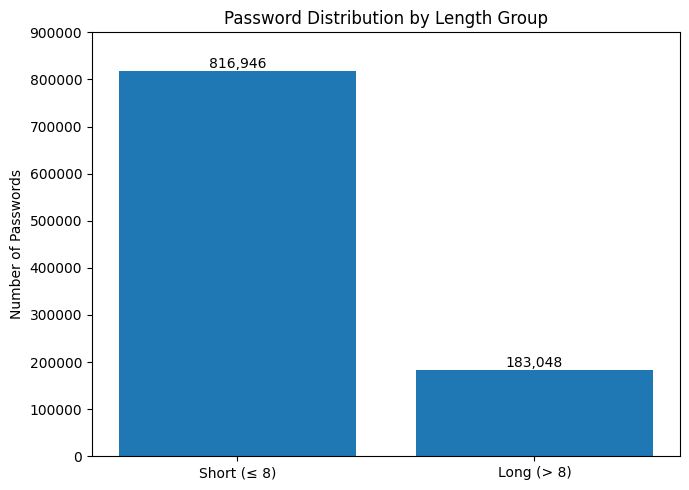

In [7]:
# Compare the two password length groups
group_counts = pd.Series({
    "Short (≤ 8)": len(short_passwords),
    "Long (> 8)": len(long_passwords)
})

plt.figure(figsize=(7, 5))
bars = plt.bar(group_counts.index, group_counts.values)

plt.title("Password Distribution by Length Group")
plt.ylabel("Number of Passwords")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, 900000)
plt.tight_layout()
plt.show()